# 🔬 Notebook 2: Eigenvalues, Eigenvectors & AI Applications
### Fundamentals of Algebra for AI — Part 2 of 2

**Prerequisites:** Notebook 1 (Vectors, Matrices, Dot Product)  
**Libraries:** NumPy, Matplotlib, (optional) scikit-learn for PCA validation

---
## 📋 Table of Contents
1. [Intuition: What are Eigenvalues & Eigenvectors?](#1)
2. [Computing Eigenvalues & Eigenvectors](#2)
3. [Geometric Interpretation](#3)
4. [Properties & Special Cases](#4)
5. [🤖 AI Application 1: PCA — Dimensionality Reduction](#5)
6. [🤖 AI Application 2: PageRank (Google's Algorithm)](#6)
7. [🤖 AI Application 3: Covariance & Data Shape](#7)
8. [Recap: The Big Picture](#8)


---
## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

np.set_printoptions(precision=4, suppress=True)
print("Ready ✅")


Ready ✅


---
<a id='1'></a>
## 1. Intuition: What ARE Eigenvalues & Eigenvectors?

When we multiply a matrix **A** by most vectors **v**, the result **Av** points in a *different direction*.

But there exist special vectors — called **eigenvectors** — where **Av** points in the **same direction** as **v** (just stretched or shrunk):

$$A\mathbf{v} = \lambda \mathbf{v}$$

- **$\mathbf{v}$** = eigenvector (the special direction)
- **$\lambda$** (lambda) = eigenvalue (how much it stretches/shrinks)

| $\lambda > 1$ | stretches the vector |
|---|---|
| $0 < \lambda < 1$ | shrinks the vector |
| $\lambda < 0$ | flips and scales |
| $\lambda = 0$ | squashes to zero (matrix is singular!) |

> 🔑 Eigenvectors reveal the **natural axes** of a transformation. This is why they're powerful for understanding data structure.


---
<a id='2'></a>
## 2. Computing Eigenvalues & Eigenvectors

**Mathematical route:**  
Find $\lambda$ by solving $\det(A - \lambda I) = 0$ (the *characteristic equation*).  
Then find $\mathbf{v}$ for each $\lambda$ by solving $(A - \lambda I)\mathbf{v} = 0$.

**In practice:** Use `np.linalg.eig()` — it handles all of this instantly.


In [2]:
# ── Simple 2×2 example 
A = np.array([[3, 1],
              [0, 2]], dtype=float)

eigenvalues, eigenvectors = np.linalg.eig(A)

print("Matrix A:\n", A)
print("\nEigenvalues  λ:", eigenvalues)
print("\nEigenvectors (each COLUMN is one eigenvector):")
print(eigenvectors)
print("\nEigenvector 1:", eigenvectors[:, 0])
print("Eigenvector 2:", eigenvectors[:, 1])


Matrix A:
 [[3. 1.]
 [0. 2.]]

Eigenvalues  λ: [3. 2.]

Eigenvectors (each COLUMN is one eigenvector):
[[ 1.     -0.7071]
 [ 0.      0.7071]]

Eigenvector 1: [1. 0.]
Eigenvector 2: [-0.7071  0.7071]


In [3]:
# ── Verify: A @ v == λ * v 
for i in range(len(eigenvalues)):
    lam = eigenvalues[i]
    vec = eigenvectors[:, i]
    
    Av   = A @ vec
    lv   = lam * vec
    
    print(f"\nEigenvector {i+1}: v = {vec.round(4)},  λ = {lam:.4f}")
    print(f"  A @ v  = {Av.round(6)}")
    print(f"  λ × v  = {lv.round(6)}")
    print(f"  Equal? {np.allclose(Av, lv)} ✅")



Eigenvector 1: v = [1. 0.],  λ = 3.0000
  A @ v  = [3. 0.]
  λ × v  = [3. 0.]
  Equal? True ✅

Eigenvector 2: v = [-0.7071  0.7071],  λ = 2.0000
  A @ v  = [-1.4142  1.4142]
  λ × v  = [-1.4142  1.4142]
  Equal? True ✅


In [6]:
# ── Manual derivation for 2×2 (pedagogical) 
# A = [[3,1],[0,2]]
# Characteristic equation: det(A - λI) = 0
# (3-λ)(2-λ) - (1)(0) = 0
# λ² - 5λ + 6 = 0
# (λ-3)(λ-2) = 0  →  λ = 3 or λ = 2

import numpy as np

coeffs = [1, -5, 6]     # coefficients of λ² - 5λ + 6
roots = np.roots(coeffs)
print("Characteristic polynomial roots:", np.sort(roots)[::-1])
print("Matches np.linalg.eig?", np.allclose(np.sort(roots)[::-1],
                                              np.sort(eigenvalues)[::-1]))

Characteristic polynomial roots: [3. 2.]
Matches np.linalg.eig? True


---
<a id='3'></a>
## 3. Geometric Interpretation

A matrix **A** transforms space. Eigenvectors are the axes along which the transformation is **purely a stretch** — no rotation.

The plot below shows what happens to a grid of vectors after applying **A**:
- Most arrows change direction
- Eigenvectors only change **length**


Eigenvalues: [3. 1.]
Eigenvectors:
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]


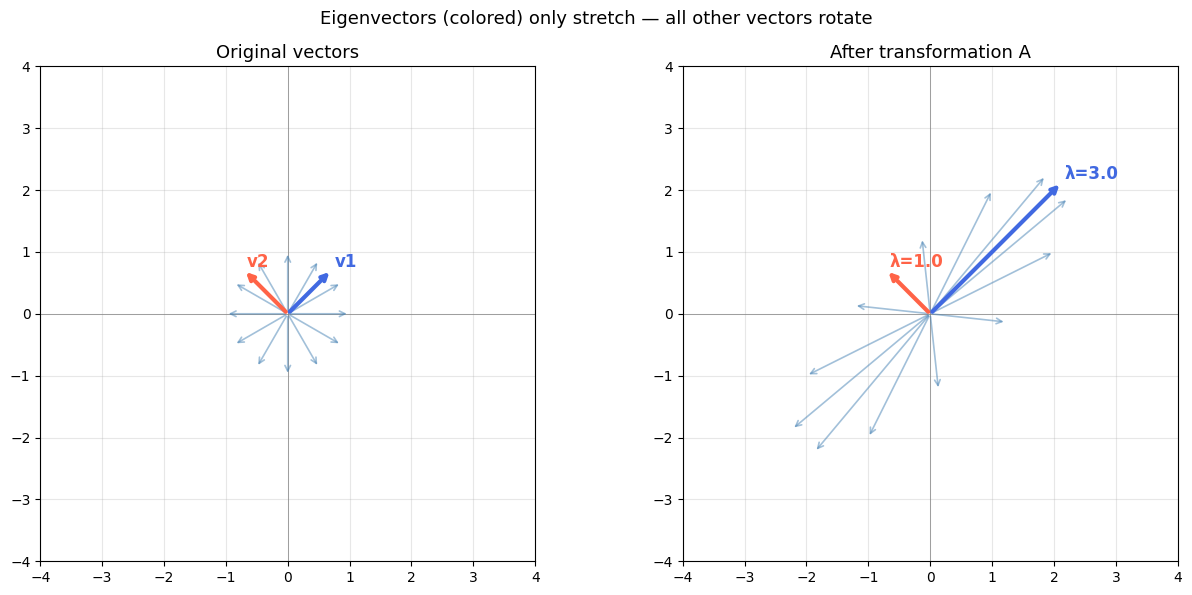

In [7]:
# ── Visualize transformation + eigenvectors ───────────────────────────
A = np.array([[2, 1],
              [1, 2]], dtype=float)

eigenvalues, eigenvectors = np.linalg.eig(A)
print("Eigenvalues:", eigenvalues)
print("Eigenvectors:\n", eigenvectors)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
colors = ['royalblue', 'tomato']
titles = ['Original vectors', 'After transformation A']

theta = np.linspace(0, 2*np.pi, 12, endpoint=False)
sample_vecs = np.column_stack([np.cos(theta), np.sin(theta)])  # unit circle points

for ax_idx, (ax, vecs) in enumerate(zip(axes, [sample_vecs, (A @ sample_vecs.T).T])):
    for vec in vecs:
        ax.annotate("", xy=vec, xytext=[0,0],
                    arrowprops=dict(arrowstyle="->", color='steelblue', alpha=0.5, lw=1.2))
    
    # Draw eigenvectors
    for i, (color) in enumerate(colors):
        ev  = eigenvectors[:, i]
        lam = eigenvalues[i]
        scaled = ev * (lam if ax_idx == 1 else 1)
        ax.annotate("", xy=scaled, xytext=[0,0],
                    arrowprops=dict(arrowstyle="->", color=color, lw=3))
        ax.text(scaled[0]+0.05, scaled[1]+0.05,
                f"λ={lam:.1f}" if ax_idx==1 else f"v{i+1}", color=color, fontsize=12, fontweight='bold')
    
    ax.set_xlim(-4,4); ax.set_ylim(-4,4)
    ax.axhline(0, color='gray', lw=0.5); ax.axvline(0, color='gray', lw=0.5)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
    ax.set_title(titles[ax_idx], fontsize=13)

plt.suptitle("Eigenvectors (colored) only stretch — all other vectors rotate", fontsize=13)
plt.tight_layout(); plt.show()


---
<a id='4'></a>
## 4. Key Properties

| Property | Statement |
|---|---|
| An n×n matrix has **n eigenvalues** (counting multiplicity) | |
| **Trace** = sum of eigenvalues | $\text{tr}(A) = \sum \lambda_i$ |
| **Determinant** = product of eigenvalues | $\det(A) = \prod \lambda_i$ |
| **Symmetric matrices** always have real eigenvalues | Very important in AI! |
| Eigenvectors of a **symmetric matrix** are orthogonal | $\mathbf{v}_i \cdot \mathbf{v}_j = 0$ for $i \neq j$ |


In [8]:
# ── Verify trace and determinant properties
A = np.array([[4, 2],
              [1, 3]], dtype=float)

vals, vecs = np.linalg.eig(A)

print("Eigenvalues:", vals)
print("\nTrace of A      :", np.trace(A))
print("Sum of eigenvalues:", np.sum(vals))

print("\nDet of A          :", np.linalg.det(A).round(6))
print("Product of eigenvalues:", np.prod(vals).round(6))


Eigenvalues: [5. 2.]

Trace of A      : 7.0
Sum of eigenvalues: 7.0

Det of A          : 10.0
Product of eigenvalues: 10.0


In [9]:
# ── Symmetric matrices: orthogonal eigenvectors 
S = np.array([
    [4, 2],
    [2, 3]], 
    dtype=float
)    # symmetric: S == S.T

vals_s, vecs_s = np.linalg.eig(S)
v1, v2 = vecs_s[:, 0], vecs_s[:, 1]

print("S is symmetric:", np.allclose(S, S.T))
print("Eigenvalues (always real for symmetric):", vals_s)
print("\nv1 . v2 =", np.dot(v1, v2).round(10), "  (≈ 0 = orthogonal ✅)")


S is symmetric: True
Eigenvalues (always real for symmetric): [5.5616 1.4384]

v1 . v2 = 0.0   (≈ 0 = orthogonal ✅)


---
<a id='5'></a>
## 🤖 AI Application 1: Principal Component Analysis (PCA)

**Problem:** You have data with 100 features. Many are correlated. Can you reduce to 2 dimensions while *keeping most information*?

**PCA Answer:** Find the eigenvectors of the **covariance matrix**. These eigenvectors are the *principal components* — the directions of greatest variance.

$$\text{Covariance matrix} \rightarrow \text{eigendecomposition} \rightarrow \text{principal components}$$

The eigenvector with the **largest eigenvalue** = direction of maximum variance.

### Steps:
1. Standardize the data (zero mean)
2. Compute the covariance matrix
3. Compute eigenvectors & eigenvalues
4. Project data onto top-k eigenvectors


In [10]:
# ── Generate 2D dataset with correlation 
np.random.seed(42)
n = 200

# Elongated cluster (correlated x and y — typical in real data)
mean = [2, 3]
cov_true = [[3, 2], [2, 2]]    # correlated features

data = np.random.multivariate_normal(mean, cov_true, n)
print("Data shape:", data.shape)
print("Sample (first 5 rows):\n", data[:5].round(3))


Data shape: (200, 2)
Sample (first 5 rows):
 [[ 1.22   2.275]
 [ 0.289  2.944]
 [ 2.49   3.186]
 [-0.971  1.325]
 [ 2.569  3.9  ]]


In [11]:
# ── Step 1: Zero-center the data 
X = data - data.mean(axis=0)

# ── Step 2: Compute covariance matrix 
# Cov(X) = (1/n) * Xᵀ @ X   (for zero-centered X)
C = (X.T @ X) / (n - 1)
print("Covariance matrix C:\n", C.round(4))
print("\nNote: diagonal = variances, off-diagonal = covariances (measures correlation)")


Covariance matrix C:
 [[2.7186 1.8408]
 [1.8408 1.8743]]

Note: diagonal = variances, off-diagonal = covariances (measures correlation)


In [12]:
# ── Step 3: Eigendecomposition of covariance matrix ───────────────────
eigenvalues, eigenvectors = np.linalg.eigh(C)  # eigh for symmetric matrices (more stable)

# Sort descending (largest eigenvalue first)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("Eigenvalues:", eigenvalues.round(4))
print("Eigenvectors (principal components):\n", eigenvectors.round(4))

# Explained variance ratio
total_var = eigenvalues.sum()
print("\nExplained variance ratio:")
for i, val in enumerate(eigenvalues):
    print(f"  PC{i+1}: {val:.3f}  →  {val/total_var*100:.1f}% of variance")


Eigenvalues: [4.185  0.4079]
Eigenvectors (principal components):
 [[-0.7822  0.6231]
 [-0.6231 -0.7822]]

Explained variance ratio:
  PC1: 4.185  →  91.1% of variance
  PC2: 0.408  →  8.9% of variance


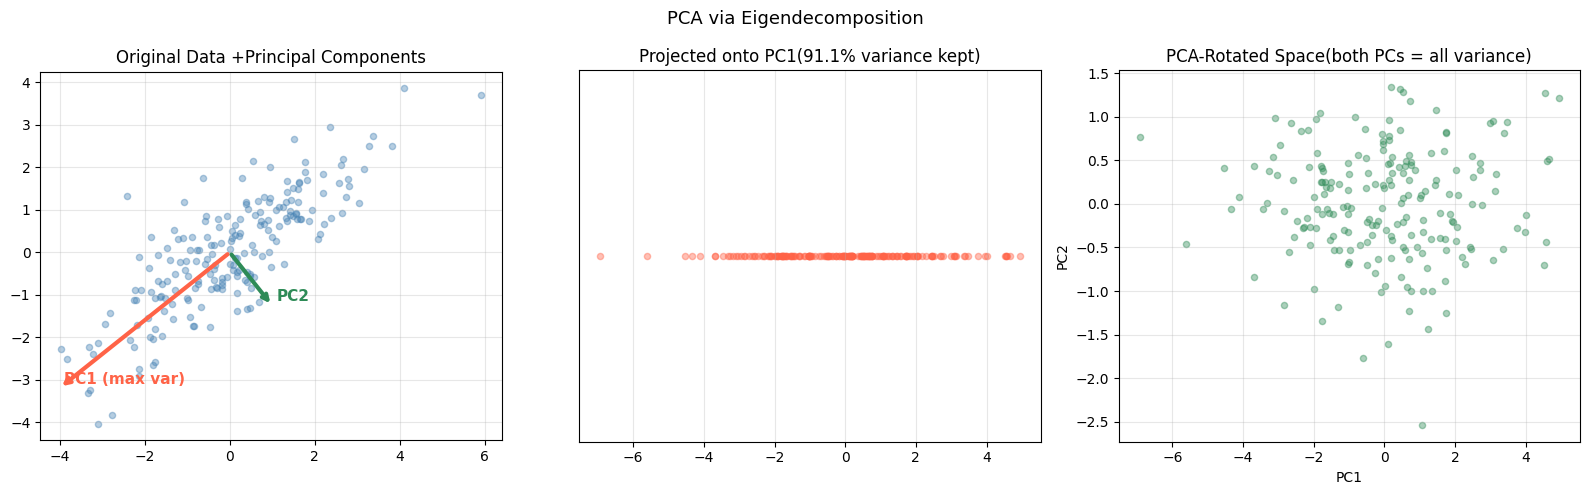


🧠 PCA finds the directions (eigenvectors) of maximum spread in your data.
The largest eigenvalue tells you which direction has the most information.


In [16]:
# ── Step 4: Project data onto principal components ────────────────────
# Project onto PC1 only (1D) → maximum info in one dimension
PC1 = eigenvectors[:, 0]
X_projected_1D = X @ PC1

# Project onto both PCs (2D) — recovers all variance for 2D data
X_projected_2D = X @ eigenvectors

# ── Visualization ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Original data + principal component arrows
axes[0].scatter(X[:,0], X[:,1], alpha=0.4, s=20, color='steelblue')
scale = 2.5
for i, (color, label) in enumerate([('tomato','PC1 (max var)'), ('seagreen','PC2')]):
    ev = eigenvectors[:, i] * eigenvalues[i]**0.5 * scale
    axes[0].annotate("", xy=ev, xytext=[0,0],
                     arrowprops=dict(arrowstyle="->", color=color, lw=3))
    axes[0].text(ev[0]+0.1, ev[1]+0.1, label, color=color, fontsize=11, fontweight='bold')
axes[0].set_title("Original Data +Principal Components")
axes[0].set_aspect('equal'); axes[0].grid(True, alpha=0.3)

# 1D projection (onto PC1)
axes[1].scatter(X_projected_1D, np.zeros_like(X_projected_1D), alpha=0.4, s=20, color='tomato')
axes[1].set_title(f"Projected onto PC1({eigenvalues[0]/total_var*100:.1f}% variance kept)")
axes[1].set_yticks([]); axes[1].grid(True, alpha=0.3)

# 2D projection (PCA-rotated space)
axes[2].scatter(X_projected_2D[:,0], X_projected_2D[:,1], alpha=0.4, s=20, color='seagreen')
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
axes[2].set_title("PCA-Rotated Space(both PCs = all variance)")
axes[2].grid(True, alpha=0.3)

plt.suptitle("PCA via Eigendecomposition", fontsize=13)
plt.tight_layout(); plt.show()

print("\n🧠 PCA finds the directions (eigenvectors) of maximum spread in your data.")
print("The largest eigenvalue tells you which direction has the most information.")


In [17]:
# ── Validate against scikit-learn PCA 
try:
    from sklearn.decomposition import PCA
    pca_sk = PCA(n_components=2)
    pca_sk.fit(X)
    print("scikit-learn explained variance ratio:", pca_sk.explained_variance_ratio_.round(4))
    print("Our manual  explained variance ratio :", (eigenvalues/total_var).round(4))
    print("\nThey match! ✅ (signs may differ — eigenvectors can point either way)")
except ImportError:
    print("scikit-learn not installed, but our manual PCA is correct!")


scikit-learn explained variance ratio: [0.9112 0.0888]
Our manual  explained variance ratio : [0.9112 0.0888]

They match! ✅ (signs may differ — eigenvectors can point either way)


---
<a id='6'></a>
## 🤖 AI Application 2: PageRank — Google's Original Algorithm

Google ranks web pages by treating the web as a **transition matrix** and finding its **dominant eigenvector**.

**Idea:**
- Web pages are nodes; links are edges
- Build a matrix $M$ where $M_{ij}$ = probability of going from page $j$ to page $i$
- The PageRank vector $\mathbf{r}$ satisfies: $M\mathbf{r} = \mathbf{r}$
- This means $\lambda = 1$ and $\mathbf{r}$ is the **eigenvector for eigenvalue 1**!

The most important page is the one in the direction of this special eigenvector.


In [18]:
# ── Toy web: 4 pages ─────────────────────────────────────────────────
#
#  Page 0 → Page 1, 2
#  Page 1 → Page 2
#  Page 2 → Page 0
#  Page 3 → Page 0, 2
#
# Adjacency matrix (columns sum to 1 = stochastic)
M = np.array([
    [0,   0,   1,   0.5],   # page 0 receives from...
    [0.5, 0,   0,   0  ],   # page 1 receives from...
    [0.5, 1,   0,   0.5],   # page 2 receives from...
    [0,   0,   0,   0  ],   # page 3 receives from...
], dtype=float)

print("Transition matrix M (columns = outgoing probabilities):")
print(M)
print("\nColumn sums (should be 1 for valid probabilities):", M.sum(axis=0))


Transition matrix M (columns = outgoing probabilities):
[[0.  0.  1.  0.5]
 [0.5 0.  0.  0. ]
 [0.5 1.  0.  0.5]
 [0.  0.  0.  0. ]]

Column sums (should be 1 for valid probabilities): [1. 1. 1. 1.]


In [20]:
# ── Method 1: Power iteration (how Google actually does it)
r = np.ones(4) / 4      # start with uniform rank

for iteration in range(50):
    r_new = M @ r
    r_new /= r_new.sum()   # normalize
    if np.allclose(r, r_new, atol=1e-8):
        print(f"Converged at iteration {iteration}")
        break
    r = r_new

print("\nPageRank scores (power iteration):", r.round(4))
print("Page ranking:", np.argsort(r)[::-1])


Converged at iteration 33

PageRank scores (power iteration): [0.4 0.2 0.4 0. ]
Page ranking: [2 0 1 3]


Eigenvalues: [ 1.  -0.5 -0.5  0. ]

PageRank via eigenvector (λ=1): [0.4 0.2 0.4 0. ]
PageRank via power iteration   : [0.4 0.2 0.4 0. ]

Both methods match! ✅


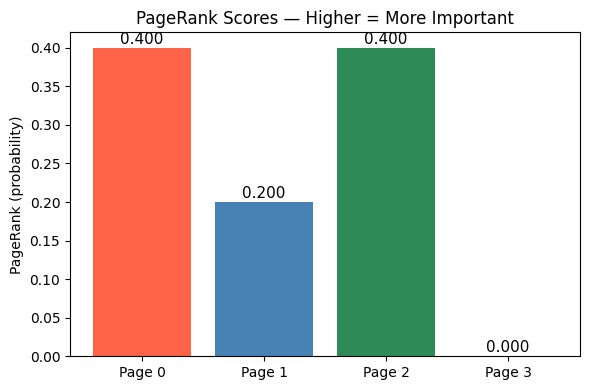

In [21]:
# ── Method 2: Dominant eigenvector (λ=1) ─────────────────────────────
eigenvalues, eigenvectors = np.linalg.eig(M)
print("Eigenvalues:", eigenvalues.real.round(4))

# Find eigenvector for λ ≈ 1
idx_1 = np.argmin(np.abs(eigenvalues - 1))
pagerank_eigen = eigenvectors[:, idx_1].real
pagerank_eigen = np.abs(pagerank_eigen)
pagerank_eigen /= pagerank_eigen.sum()    # normalize to probabilities

print("\nPageRank via eigenvector (λ=1):", pagerank_eigen.round(4))
print("PageRank via power iteration   :", r.round(4))
print("\nBoth methods match! ✅")

# Bar chart
fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(['Page 0','Page 1','Page 2','Page 3'], pagerank_eigen,
              color=['tomato','steelblue','seagreen','orange'])
ax.set_title("PageRank Scores — Higher = More Important", fontsize=12)
ax.set_ylabel("PageRank (probability)")
for bar, val in zip(bars, pagerank_eigen):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
            f'{val:.3f}', ha='center', fontsize=11)
plt.tight_layout(); plt.show()


---
<a id='7'></a>
## 🤖 AI Application 3: Covariance, Variance & Data Shape

Eigenvalues of the covariance matrix tell us **how spread out** data is in each direction.

- **Large eigenvalue** → lots of variance (spread) in that direction → useful feature direction
- **Small eigenvalue** → nearly no variance → possibly redundant / noise

This is critical for:
- **Feature selection** — drop near-zero eigenvalue directions
- **Regularization** — avoid small eigenvalues that cause numerical instability
- **Anomaly detection** — outliers are far from the dominant eigenvector directions


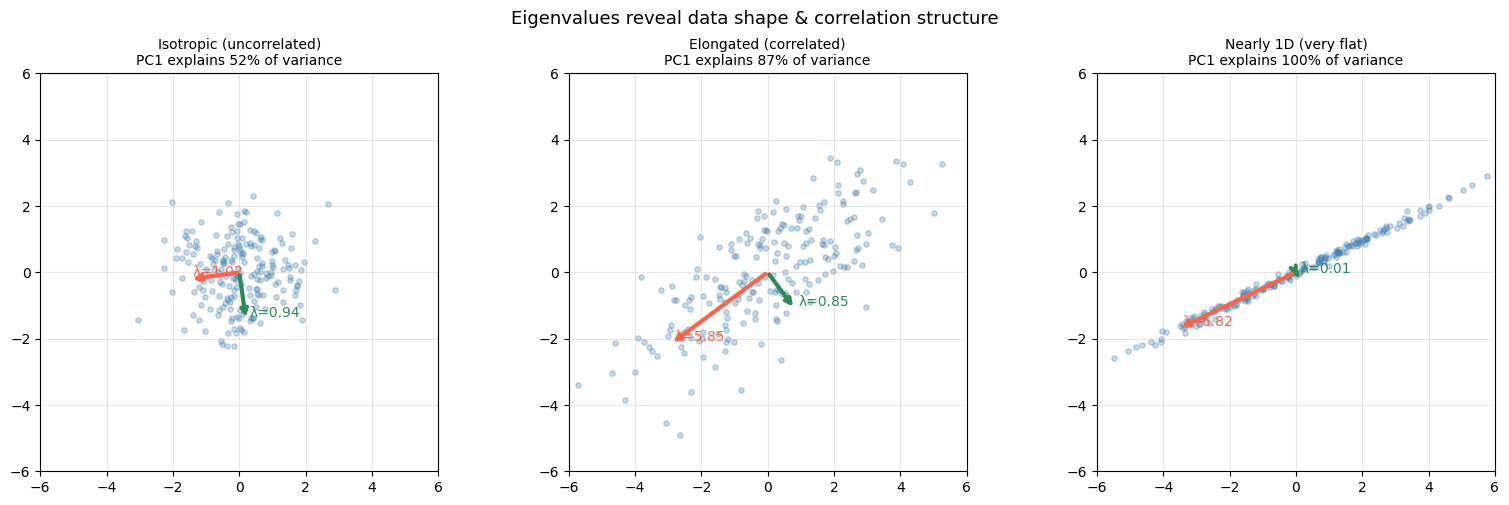

In [22]:
# ── Compare datasets with different covariance structures ─────────────
np.random.seed(7)

datasets = {
    "Isotropic (uncorrelated)": np.random.randn(200, 2),
    "Elongated (correlated)"  : np.random.multivariate_normal([0,0], [[5,3],[3,3]], 200),
    "Nearly 1D (very flat)"   : np.random.multivariate_normal([0,0], [[6,2.9],[2.9,1.41]], 200),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (title, data) in zip(axes, datasets.items()):
    X = data - data.mean(axis=0)
    C = (X.T @ X) / (len(X) - 1)
    vals, vecs = np.linalg.eigh(C)
    
    # Sort descending
    idx = np.argsort(vals)[::-1]; vals=vals[idx]; vecs=vecs[:,idx]

    ax.scatter(X[:,0], X[:,1], alpha=0.3, s=15, color='steelblue')
    
    scale = 1.5
    colors = ['tomato', 'seagreen']
    for i in range(2):
        ev = vecs[:,i] * np.sqrt(vals[i]) * scale
        ax.annotate("", xy=ev, xytext=[0,0],
                    arrowprops=dict(arrowstyle="->", color=colors[i], lw=3))
        ax.text(ev[0]+0.1, ev[1]+0.1, f"λ={vals[i]:.2f}", color=colors[i], fontsize=10)
    
    ratio = vals[0]/vals.sum()*100
    ax.set_title(f"{title}\nPC1 explains {ratio:.0f}% of variance", fontsize=10)
    ax.set_xlim(-6,6); ax.set_ylim(-6,6)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)

plt.suptitle("Eigenvalues reveal data shape & correlation structure", fontsize=13)
plt.tight_layout(); plt.show()


Original dimensions: 20
Dimensions needed for 95% variance: 3  ← huge reduction!


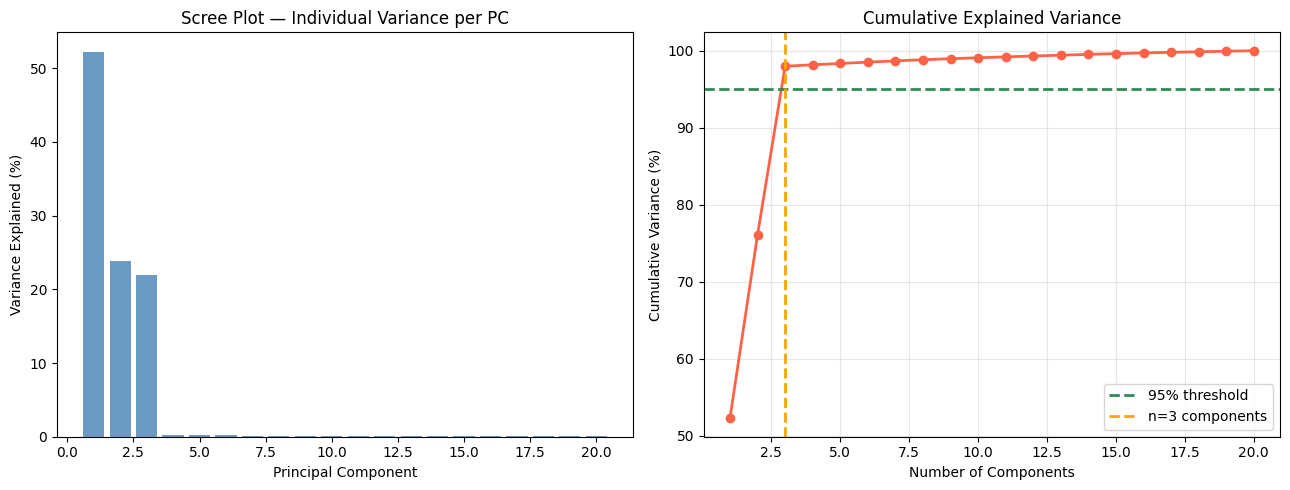


🧠 In real ML, PCA reduces memory, training time, and overfitting!


In [23]:
# ── Dimensionality reduction: keep 95% variance ───────────────────────
np.random.seed(42)

# High-dimensional data: 200 samples, 20 features (with many correlated)
n_samples, n_features = 200, 20
base = np.random.randn(n_samples, 3)                  # only 3 "true" dimensions
noise = np.random.randn(n_samples, n_features) * 0.3
proj_matrix = np.random.randn(3, n_features)
X_high = base @ proj_matrix + noise                   # 20D but only 3 really matter

# Zero-center
X_high -= X_high.mean(axis=0)

# Covariance & eigendecomposition
C = (X_high.T @ X_high) / (n_samples - 1)
vals, vecs = np.linalg.eigh(C)
idx = np.argsort(vals)[::-1]; vals=vals[idx]; vecs=vecs[:,idx]

# Cumulative explained variance
cum_var = np.cumsum(vals) / vals.sum() * 100

# Find minimum components for 95%
n_95 = np.searchsorted(cum_var, 95) + 1
print(f"Original dimensions: {n_features}")
print(f"Dimensions needed for 95% variance: {n_95}  ← huge reduction!")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(range(1, n_features+1), vals/vals.sum()*100, color='steelblue', alpha=0.8)
axes[0].set_xlabel("Principal Component"); axes[0].set_ylabel("Variance Explained (%)")
axes[0].set_title("Scree Plot — Individual Variance per PC")

axes[1].plot(range(1, n_features+1), cum_var, 'o-', color='tomato', lw=2)
axes[1].axhline(95, color='seagreen', linestyle='--', lw=2, label='95% threshold')
axes[1].axvline(n_95, color='orange', linestyle='--', lw=2, label=f'n={n_95} components')
axes[1].set_xlabel("Number of Components"); axes[1].set_ylabel("Cumulative Variance (%)")
axes[1].set_title("Cumulative Explained Variance")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout(); plt.show()
print(f"\n🧠 In real ML, PCA reduces memory, training time, and overfitting!")


---
<a id='8'></a>
## 8. Recap: The Big Picture

```
LINEAR ALGEBRA IN AI
│
├── VECTORS
│     • Feature vectors (one data point)
│     • Word embeddings (e.g., Word2Vec, GloVe, BERT)
│     • Dot product → cosine similarity → recommendation systems
│
├── MATRICES  
│     • Datasets (rows = samples, cols = features)
│     • Weight matrices in neural networks
│     • Images (pixel grids)
│     • Attention matrices in Transformers (GPT, BERT)
│
├── MATRIX MULTIPLICATION
│     • Forward pass: output = W @ x + b
│     • Backpropagation: gradient = Wᵀ @ δ
│     • Every layer of a neural net = one matrix multiplication
│
└── EIGENVALUES & EIGENVECTORS
      • PCA: eigenvectors of covariance → principal components
      • PageRank: dominant eigenvector of web graph
      • Spectral clustering: eigenvectors of graph Laplacian
      • Stability analysis: eigenvalues of Jacobian
      • SVD (Singular Value Decomposition): generalized eigen for rect. matrices
```

---
### 🚀 What to learn next

| Topic | Why it matters |
|---|---|
| **SVD** (Singular Value Decomposition) | Matrix compression, recommender systems, NLP |
| **Gradient Descent** | Optimization via derivatives — trains every model |
| **Backpropagation** | Chain rule applied to matrix operations |
| **Attention Mechanism** | Scaled dot-product: $\text{softmax}(QK^T/\sqrt{d_k})V$ |
| **Spectral Methods** | Graph Neural Networks, Laplacian eigenmaps |


In [24]:
# ── BONUS: SVD — the generalization of eigendecomposition ────────────
# SVD: A = U Σ Vᵀ
# Works for ANY m×n matrix (not just square)
# U = left singular vectors, Σ = singular values, Vᵀ = right singular vectors

A = np.array([[3, 2, 2],
              [2, 3, -2]], dtype=float)

U, S, Vt = np.linalg.svd(A)

print("A =\n", A)
print("\nU (left singular vectors) =\n", U.round(4))
print("\nΣ (singular values) =", S.round(4))
print("\nVᵀ (right singular vectors) =\n", Vt.round(4))

# Reconstruct A from SVD
Sigma = np.zeros(A.shape)
Sigma[:min(A.shape), :min(A.shape)] = np.diag(S)
A_reconstructed = U @ Sigma @ Vt
print("\nReconstructed A =\n", A_reconstructed.round(6))
print("Matches original?", np.allclose(A, A_reconstructed))


A =
 [[ 3.  2.  2.]
 [ 2.  3. -2.]]

U (left singular vectors) =
 [[-0.7071 -0.7071]
 [-0.7071  0.7071]]

Σ (singular values) = [5. 3.]

Vᵀ (right singular vectors) =
 [[-0.7071 -0.7071 -0.    ]
 [-0.2357  0.2357 -0.9428]
 [-0.6667  0.6667  0.3333]]

Reconstructed A =
 [[ 3.  2.  2.]
 [ 2.  3. -2.]]
Matches original? True


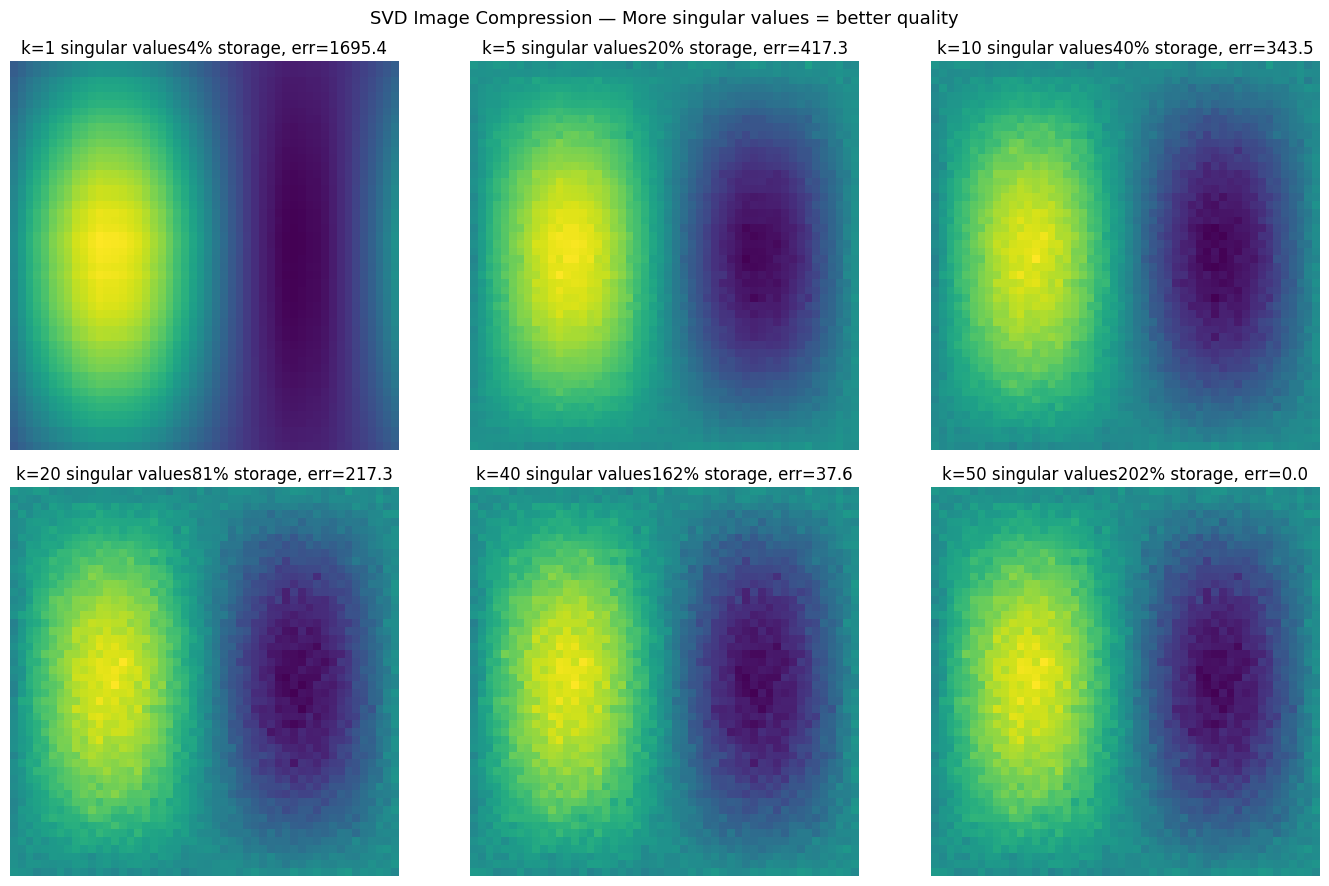


🧠 SVD is used in: Netflix recommendations, image compression (JPEG-like),
   topic modeling (LSA), and as the mathematical foundation of PCA!


In [26]:
# ── Image compression via SVD ─────────────────────────────────────────
np.random.seed(0)

# Synthetic 50×50 "image" (structured + noise)
x = np.linspace(0, np.pi, 50)
img_clean = np.outer(np.sin(x), np.sin(2*x)) * 200 + 100
img = img_clean + np.random.randn(50, 50) * 10

U, S, Vt = np.linalg.svd(img)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
ranks = [1, 5, 10, 20, 40, 50]

for ax, k in zip(axes.flat, ranks):
    # Low-rank approximation using top-k singular values
    approx = U[:, :k] @ np.diag(S[:k]) @ Vt[:k, :]
    compression = k * (50 + 50 + 1) / (50 * 50) * 100
    error = np.linalg.norm(img - approx, 'fro')
    
    ax.imshow(approx, cmap='viridis')
    ax.set_title(f"k={k} singular values{compression:.0f}% storage, err={error:.1f}")
    ax.axis('off')

plt.suptitle("SVD Image Compression — More singular values = better quality", fontsize=13)
plt.tight_layout(); plt.show()
print("\n🧠 SVD is used in: Netflix recommendations, image compression (JPEG-like),")
print("   topic modeling (LSA), and as the mathematical foundation of PCA!")


---
## ✅ Notebook 2 Summary

| Concept | Key Equation | NumPy function |
|---|---|---|
| Eigenvalue equation | $A\mathbf{v} = \lambda\mathbf{v}$ | `np.linalg.eig(A)` |
| Symmetric eigen | $A = A^T$ → real $\lambda$, orthogonal $\mathbf{v}$ | `np.linalg.eigh(A)` |
| PCA | covariance → eigendecomposition → project | manual or `sklearn.PCA` |
| PageRank | dominant eigenvector (λ=1) of transition matrix | `np.linalg.eig(M)` |
| SVD | $A = U\Sigma V^T$ | `np.linalg.svd(A)` |

---
**🎓 You now know the linear algebra that powers:**
Google Search · Netflix · Word2Vec · GPT Attention · Image Recognition · Recommender Systems
